In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn streamlit joblib

In [2]:
!pip install -q ucimlrepo openpyxl

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Load the original UCI Online Retail dataset
online_retail = fetch_ucirepo(id=352)

df = online_retail.data.features.copy()

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Dataset shape: (541909, 6)


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Column names:
['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB


In [5]:
print("Columns in df:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Columns in df:
['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 rows:


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [6]:
import pandas as pd
import requests
from io import BytesIO

# Download the original Excel dataset from UCI
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url, timeout=120)
response.raise_for_status()

import zipfile

with zipfile.ZipFile(BytesIO(response.content)) as z:
    excel_file = [
        name for name in z.namelist()
        if name.lower().endswith(".xlsx")
    ][0]

    with z.open(excel_file) as f:
        df = pd.read_excel(f, engine="openpyxl")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
# Module 1: Data Cleaning

clean_df = df.copy()

# Store original row count
original_rows = len(clean_df)

# Convert data types
clean_df["InvoiceNo"] = clean_df["InvoiceNo"].astype(str).str.strip()
clean_df["StockCode"] = clean_df["StockCode"].astype(str).str.strip()
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"], errors="coerce"
)
clean_df["CustomerID"] = pd.to_numeric(
    clean_df["CustomerID"], errors="coerce"
)

# Count duplicates before removing
duplicate_count = clean_df.duplicated().sum()

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates().copy()

rows_after_duplicates = len(clean_df)

# Count and remove missing essential values
missing_customer_rows = clean_df["CustomerID"].isna().sum()

required_columns = [
    "InvoiceNo", "StockCode", "InvoiceDate",
    "Quantity", "UnitPrice", "CustomerID", "Country"
]

clean_df = clean_df.dropna(subset=required_columns).copy()

# Identify cancelled invoices
cancelled_mask = clean_df["InvoiceNo"].str.upper().str.startswith("C")
cancelled_rows = cancelled_mask.sum()

# Remove cancelled invoices
clean_df = clean_df[~cancelled_mask].copy()

# Remove invalid sales
invalid_rows = (
    (clean_df["Quantity"] <= 0) |
    (clean_df["UnitPrice"] <= 0)
).sum()

clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

# Calculate revenue
clean_df["Revenue"] = clean_df["Quantity"] * clean_df["UnitPrice"]

# Save cleaned data
clean_df.to_csv("cleaned_online_retail.csv", index=False)

# Display cleaning report
print("DATA CLEANING COMPLETED!")
print("-" * 40)
print("Original rows:", original_rows)
print("Duplicate rows removed:", duplicate_count)
print("Rows after duplicate removal:", rows_after_duplicates)
print("Rows with missing CustomerID initially:", missing_customer_rows)
print("Cancelled invoice rows removed:", cancelled_rows)
print("Invalid quantity/price rows removed:", invalid_rows)
print("Final cleaned rows:", len(clean_df))
print("Unique customers:", clean_df["CustomerID"].nunique())
print("Total revenue (£):", round(clean_df["Revenue"].sum(), 2))

display(clean_df.head())

DATA CLEANING COMPLETED!
----------------------------------------
Original rows: 541909
Duplicate rows removed: 5268
Rows after duplicate removal: 536641
Rows with missing CustomerID initially: 135037
Cancelled invoice rows removed: 8872
Invalid quantity/price rows removed: 40
Final cleaned rows: 392692
Unique customers: 4338
Total revenue (£): 8887208.89


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [8]:
from google.colab import files

files.download("cleaned_online_retail.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# Module 2: Basic Statistics

print("Total transactions:", clean_df["InvoiceNo"].nunique())
print("Total unique customers:", clean_df["CustomerID"].nunique())
print("Total unique products:", clean_df["StockCode"].nunique())
print("Total countries:", clean_df["Country"].nunique())
print("Total quantity sold:", clean_df["Quantity"].sum())
print("Total revenue (£):", round(clean_df["Revenue"].sum(), 2))

print("\nDataset date range:")
print("From:", clean_df["InvoiceDate"].min())
print("To:", clean_df["InvoiceDate"].max())

display(clean_df.describe())

Total transactions: 18532
Total unique customers: 4338
Total unique products: 3665
Total countries: 37
Total quantity sold: 5152002
Total revenue (£): 8887208.89

Dataset date range:
From: 2010-12-01 08:26:00
To: 2011-12-09 12:50:00


,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue
count,392692.000000,392692,392692.000000,392692.000000,392692.000000
mean,13.119702,2011-07-10 19:13:07.771892480,3.125914,15287.843865,22.631500
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,2.000000,2011-04-07 11:12:00,1.250000,13955.000000,4.950000
50%,6.000000,2011-07-31 12:02:00,1.950000,15150.000000,12.450000
75%,12.000000,2011-10-20 12:53:00,3.750000,16791.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000,168469.600000
std,180.492832,NaN,22.241836,1713.539549,311.099224


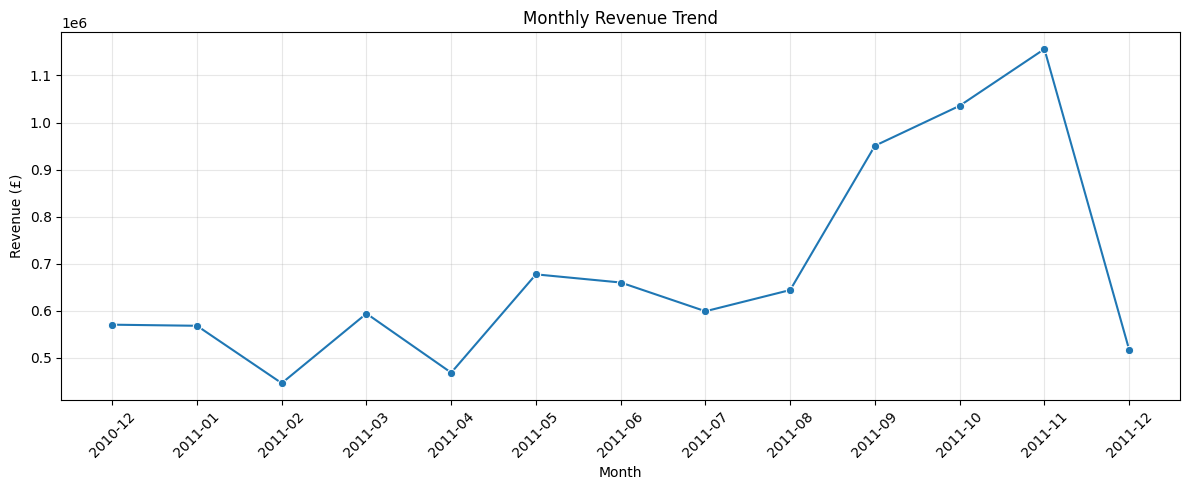

,Month,Revenue
0,2010-12,570422.730
1,2011-01,568101.310
2,2011-02,446084.920
3,2011-03,594081.760
4,2011-04,468374.331
5,2011-05,677355.150
6,2011-06,660046.050
7,2011-07,598962.901
8,2011-08,644051.040
9,2011-09,950690.202


In [10]:
# Monthly Revenue Analysis

clean_df["Month"] = clean_df["InvoiceDate"].dt.to_period("M").astype(str)

monthly_revenue = (
    clean_df.groupby("Month", as_index=False)["Revenue"]
    .sum()
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_revenue)

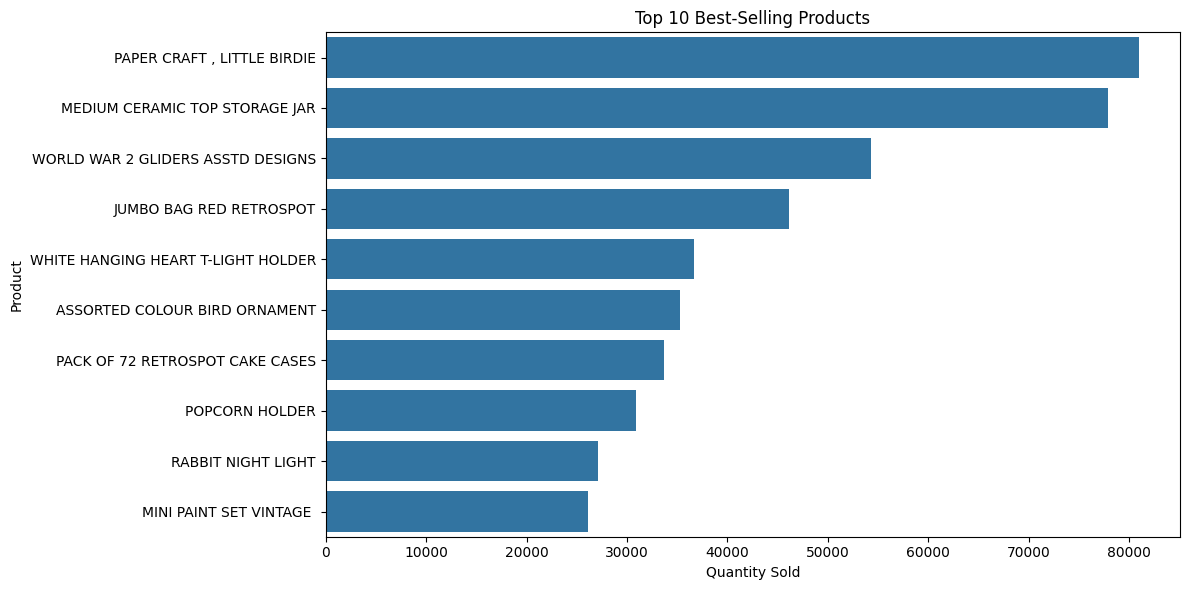

,Description,Quantity
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,77916
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319
3,JUMBO BAG RED RETROSPOT,46078
4,WHITE HANGING HEART T-LIGHT HOLDER,36706
5,ASSORTED COLOUR BIRD ORNAMENT,35263
6,PACK OF 72 RETROSPOT CAKE CASES,33670
7,POPCORN HOLDER,30919
8,RABBIT NIGHT LIGHT,27153
9,MINI PAINT SET VINTAGE,26076


In [11]:
# Top 10 products by quantity sold

top_products = (
    clean_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_products,
    x="Quantity",
    y="Description"
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

display(top_products)

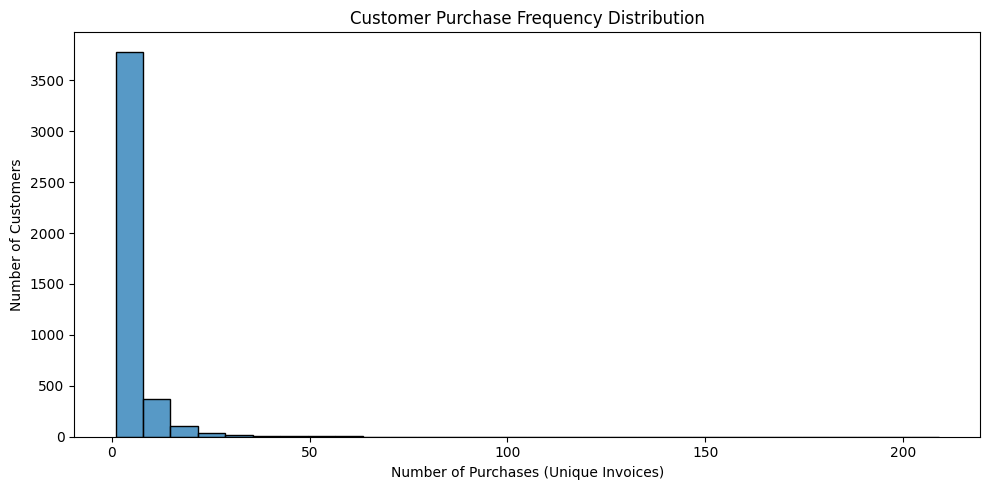

Average purchases per customer: 4.27


,CustomerID,PurchaseFrequency
326,12748.0,209
1879,14911.0,201
4010,17841.0,124
562,13089.0,97
1661,14606.0,93
2176,15311.0,91
481,12971.0,86
1689,14646.0,73
2702,16029.0,63
795,13408.0,62


In [12]:
# Count unique invoices per customer

purchase_frequency = (
    clean_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index(name="PurchaseFrequency")
)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=purchase_frequency,
    x="PurchaseFrequency",
    bins=30
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Purchases (Unique Invoices)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Average purchases per customer:",
      round(purchase_frequency["PurchaseFrequency"].mean(), 2))

display(
    purchase_frequency.sort_values(
        "PurchaseFrequency", ascending=False
    ).head(10)
)

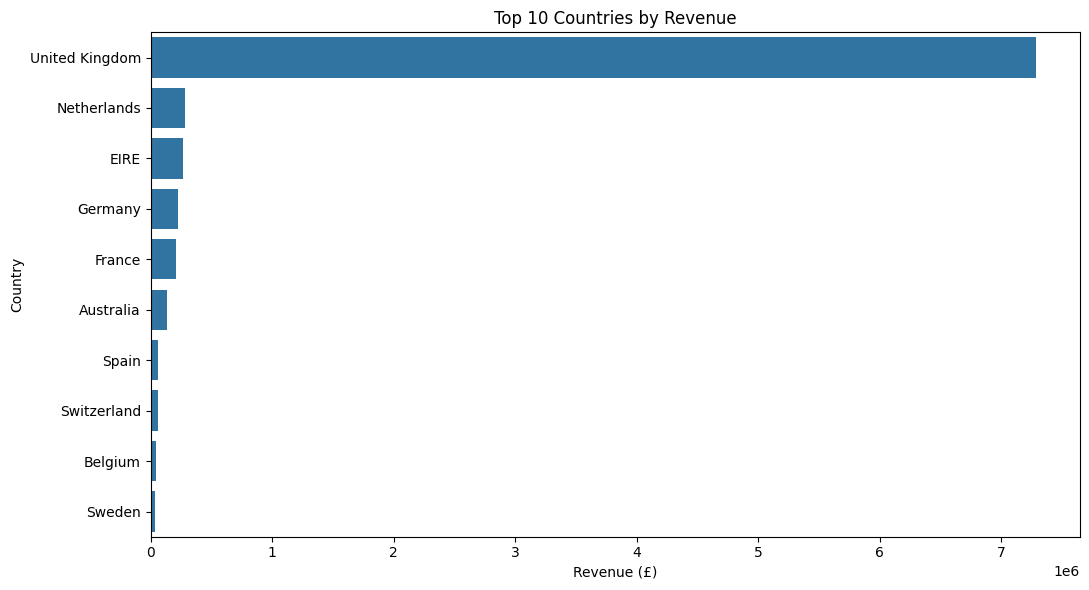

,Country,Revenue
0,United Kingdom,7285024.644
1,Netherlands,285446.340
2,EIRE,265262.460
3,Germany,228678.400
4,France,208934.310
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,56443.950
8,Belgium,41196.340
9,Sweden,38367.830


In [13]:
# Revenue by country

country_revenue = (
    clean_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=country_revenue,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

display(country_revenue)

In [14]:
monthly_revenue.to_csv("monthly_revenue.csv", index=False)
top_products.to_csv("top_products.csv", index=False)
purchase_frequency.to_csv("purchase_frequency.csv", index=False)
country_revenue.to_csv("country_revenue.csv", index=False)

print("EDA completed successfully!")
print("All four analysis reports saved.")

EDA completed successfully!
All four analysis reports saved.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reference date: one day after the last transaction
reference_date = clean_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = clean_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM analysis completed!")
print("Number of customers:", len(rfm))

display(rfm.head(10))
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

RFM analysis completed!
Number of customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40
5,12352.0,37,8,2506.04
6,12353.0,205,1,89.00
7,12354.0,233,1,1079.40
8,12355.0,215,1,459.40
9,12356.0,23,3,2811.43


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,93.059474,4.272015,2048.688081
std,100.012264,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.750000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [16]:
# Assign RFM scores from 1 to 5

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,1,1,5,115
1,12347.0,3,7,4310.00,5,5,5,555
2,12348.0,76,4,1797.24,2,4,4,244
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,311,1,334.40,1,1,2,112
5,12352.0,37,8,2506.04,3,5,5,355
6,12353.0,205,1,89.00,1,1,1,111
7,12354.0,233,1,1079.40,1,1,4,114
8,12355.0,215,1,459.40,1,1,2,112
9,12356.0,23,3,2811.43,4,3,5,435


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select RFM features
rfm_features = ["Recency", "Frequency", "Monetary"]

# Reduce skewness of frequency and monetary values
X = rfm[rfm_features].copy()
X["Frequency"] = np.log1p(X["Frequency"])
X["Monetary"] = np.log1p(X["Monetary"])

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print(rfm["Cluster"].value_counts().sort_index())

display(rfm.head(10))

K-Means clustering completed!
Cluster
0    1377
1     573
2     938
3    1450
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Cluster
0,12346.0,326,1,77183.60,1,1,5,115,3
1,12347.0,3,7,4310.00,5,5,5,555,1
2,12348.0,76,4,1797.24,2,4,4,244,3
3,12349.0,19,1,1757.55,4,1,4,414,3
4,12350.0,311,1,334.40,1,1,2,112,2
5,12352.0,37,8,2506.04,3,5,5,355,1
6,12353.0,205,1,89.00,1,1,1,111,2
7,12354.0,233,1,1079.40,1,1,4,114,2
8,12355.0,215,1,459.40,1,1,2,112,2
9,12356.0,23,3,2811.43,4,3,5,435,3


In [18]:
# Summarize cluster characteristics
cluster_summary = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(cluster_summary)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,1377,58.60,1.51,384.22
1,573,20.32,15.81,9799.78
2,938,259.92,1.37,385.39
3,1450,46.58,4.21,1642.33


In [19]:
# Rank clusters by spending and purchase activity
summary = cluster_summary.copy()

# High-value customers: high spend and frequent purchases
high_value_cluster = (
    summary["Avg_Monetary"] *
    (summary["Avg_Frequency"] + 1)
).idxmax()

# Inactive customers: longest time since last purchase
inactive_cluster = summary["Avg_Recency"].idxmax()

remaining_clusters = [
    c for c in summary.index
    if c not in [high_value_cluster, inactive_cluster]
]

# Among remaining clusters, the more recent one is relatively active
if len(remaining_clusters) == 2:
    loyal_cluster = summary.loc[
        remaining_clusters, "Avg_Frequency"
    ].idxmax()

    occasional_cluster = next(
        c for c in remaining_clusters if c != loyal_cluster
    )
else:
    loyal_cluster = remaining_clusters[0]
    occasional_cluster = remaining_clusters[-1]

segment_names = {
    high_value_cluster: "High-Value Customers",
    inactive_cluster: "Inactive / At-Risk Customers",
    loyal_cluster: "Loyal Customers",
    occasional_cluster: "Occasional Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("Customer segment counts:")
display(rfm["Segment"].value_counts().to_frame("Customers"))

display(rfm.head(10))

Customer segment counts:


,Customers
Segment,
Loyal Customers,1450
Occasional Customers,1377
Inactive / At-Risk Customers,938
High-Value Customers,573


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Cluster,Segment
0,12346.0,326,1,77183.60,1,1,5,115,3,Loyal Customers
1,12347.0,3,7,4310.00,5,5,5,555,1,High-Value Customers
2,12348.0,76,4,1797.24,2,4,4,244,3,Loyal Customers
3,12349.0,19,1,1757.55,4,1,4,414,3,Loyal Customers
4,12350.0,311,1,334.40,1,1,2,112,2,Inactive / At-Risk Customers
5,12352.0,37,8,2506.04,3,5,5,355,1,High-Value Customers
6,12353.0,205,1,89.00,1,1,1,111,2,Inactive / At-Risk Customers
7,12354.0,233,1,1079.40,1,1,4,114,2,Inactive / At-Risk Customers
8,12355.0,215,1,459.40,1,1,2,112,2,Inactive / At-Risk Customers
9,12356.0,23,3,2811.43,4,3,5,435,3,Loyal Customers


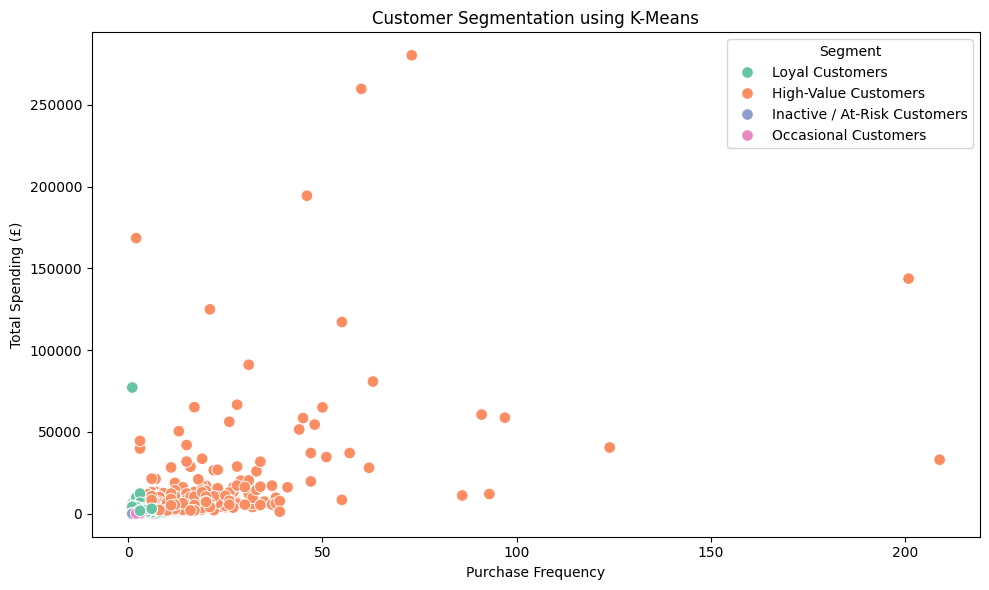

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Segment",
    palette="Set2",
    s=70
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending (£)")
plt.tight_layout()
plt.show()

In [21]:
# Save customer-level RFM and cluster results
rfm.to_csv("customer_segments.csv", index=False)

# Save cluster summary
cluster_summary.to_csv("cluster_summary.csv")

print("Customer segmentation completed!")
print("Saved: customer_segments.csv")
print("Saved: cluster_summary.csv")

Customer segmentation completed!
Saved: customer_segments.csv
Saved: cluster_summary.csv


In [22]:
# MODULE 4: Prepare a leakage-free prediction dataset

import pandas as pd
import numpy as np

# Ensure dates are in datetime format
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"])

# Work with customer transactions
transactions = clean_df.copy()
transactions["CustomerID"] = transactions["CustomerID"].astype(int)

# Use monthly prediction dates
# Each date must have at least 30 future days available
first_date = pd.Timestamp("2011-04-01")
last_date = pd.Timestamp("2011-10-01")

snapshot_dates = pd.date_range(
    start=first_date,
    end=last_date,
    freq="MS"
)

rows = []

for snapshot in snapshot_dates:
    # All information strictly before prediction date
    past = transactions[
        transactions["InvoiceDate"] < snapshot
    ].copy()

    # Transactions in the next 30 days: target only
    future = transactions[
        (transactions["InvoiceDate"] >= snapshot) &
        (transactions["InvoiceDate"] < snapshot + pd.Timedelta(days=30))
    ]

    if past.empty:
        continue

    # Recent 90-day history
    recent = past[
        past["InvoiceDate"] >= snapshot - pd.Timedelta(days=90)
    ]

    # Customers who have purchased before this snapshot
    known_customers = past["CustomerID"].unique()

    # Past-only customer features
    lifetime = past.groupby("CustomerID").agg(
        LifetimeInvoices=("InvoiceNo", "nunique"),
        LifetimeRevenue=("Revenue", "sum"),
        LastPurchase=("InvoiceDate", "max")
    )

    recent_features = recent.groupby("CustomerID").agg(
        RecentInvoices=("InvoiceNo", "nunique"),
        RecentRevenue=("Revenue", "sum"),
        RecentQuantity=("Quantity", "sum")
    )

    # Customer's future purchase label
    future_customers = set(future["CustomerID"].unique())

    frame = pd.DataFrame({"CustomerID": known_customers})
    frame = frame.join(lifetime, on="CustomerID")
    frame = frame.join(recent_features, on="CustomerID")

    frame["RecencyDays"] = (
        snapshot - frame["LastPurchase"]
    ).dt.days

    frame["RecentInvoices"] = frame["RecentInvoices"].fillna(0)
    frame["RecentRevenue"] = frame["RecentRevenue"].fillna(0)
    frame["RecentQuantity"] = frame["RecentQuantity"].fillna(0)

    frame["SnapshotDate"] = snapshot
    frame["PurchasedNext30Days"] = (
        frame["CustomerID"].isin(future_customers).astype(int)
    )

    rows.append(frame.drop(columns=["LastPurchase"]))

model_data = pd.concat(rows, ignore_index=True)

print("Prediction dataset created!")
print("Rows and columns:", model_data.shape)
print("\nTarget distribution:")
print(model_data["PurchasedNext30Days"].value_counts())
print("\nPurchase rate:")
print(
    round(model_data["PurchasedNext30Days"].mean() * 100, 2),
    "%"
)

display(model_data.head())

Prediction dataset created!
Rows and columns: (20327, 9)

Target distribution:
PurchasedNext30Days
0    14834
1     5493
Name: count, dtype: int64

Purchase rate:
27.02 %


,CustomerID,LifetimeInvoices,LifetimeRevenue,RecentInvoices,RecentRevenue,RecentQuantity,RecencyDays,SnapshotDate,PurchasedNext30Days
0,17850,34,5391.21,0.0,0.00,0.0,119,2011-04-01,0
1,13047,5,1252.68,2.0,886.05,404.0,1,2011-04-01,0
2,12583,4,2620.43,3.0,1764.57,1270.0,20,2011-04-01,0
3,13748,1,204.00,0.0,0.00,0.0,120,2011-04-01,1
4,15100,3,876.00,1.0,175.20,16.0,80,2011-04-01,0


In [23]:
from sklearn.model_selection import train_test_split

# Chronological split
train_data = model_data[
    model_data["SnapshotDate"] <= pd.Timestamp("2011-07-01")
].copy()

test_data = model_data[
    model_data["SnapshotDate"] >= pd.Timestamp("2011-08-01")
].copy()

feature_columns = [
    "RecencyDays",
    "LifetimeInvoices",
    "LifetimeRevenue",
    "RecentInvoices",
    "RecentRevenue",
    "RecentQuantity"
]

target_column = "PurchasedNext30Days"

X_train = train_data[feature_columns]
y_train = train_data[target_column]

X_test = test_data[feature_columns]
y_test = test_data[target_column]

print("Training period:",
      train_data["SnapshotDate"].min(),
      "to", train_data["SnapshotDate"].max())

print("Testing period:",
      test_data["SnapshotDate"].min(),
      "to", test_data["SnapshotDate"].max())

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training period: 2011-04-01 00:00:00 to 2011-07-01 00:00:00
Testing period: 2011-08-01 00:00:00 to 2011-10-01 00:00:00
Training rows: 10246
Testing rows: 10081

Training target distribution:
PurchasedNext30Days
0    7446
1    2800
Name: count, dtype: int64

Testing target distribution:
PurchasedNext30Days
0    7388
1    2693
Name: count, dtype: int64


In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [25]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest training completed!")

Random Forest training completed!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.709,0.465,0.596,0.522,0.739
1,Random Forest,0.726,0.489,0.570,0.526,0.733


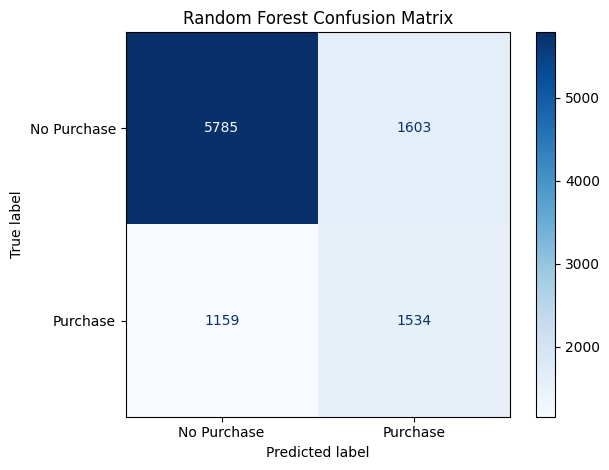

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

def evaluate_model(name, y_true, predictions, probabilities):
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(y_true, probabilities)
            if y_true.nunique() == 2 else np.nan
        )
    }
    return results

results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        y_test, logistic_predictions, logistic_probabilities
    ),
    evaluate_model(
        "Random Forest",
        y_test, rf_predictions, rf_probabilities
    )
])

display(results.round(3))

# Confusion matrix for Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [27]:
# Save test predictions for dashboard use
predictions_output = test_data[
    ["CustomerID", "SnapshotDate", "PurchasedNext30Days"]
].copy()

predictions_output["LogisticRegressionProbability"] = (
    logistic_probabilities
)

predictions_output["RandomForestProbability"] = (
    rf_probabilities
)

predictions_output.to_csv(
    "purchase_predictions.csv",
    index=False
)

print("Predictions saved successfully!")
display(predictions_output.head(10))

Predictions saved successfully!


,CustomerID,SnapshotDate,PurchasedNext30Days,LogisticRegressionProbability,RandomForestProbability
10246,17850,2011-08-01,0,0.999689,0.162686
10247,13047,2011-08-01,1,0.792651,0.775506
10248,12583,2011-08-01,1,0.887081,0.917865
10249,13748,2011-08-01,0,0.435210,0.224093
10250,15100,2011-08-01,0,0.407036,0.403961
10251,15291,2011-08-01,0,0.919247,0.774665
10252,14688,2011-08-01,1,0.983832,0.984638
10253,17809,2011-08-01,1,0.791717,0.775879
10254,15311,2011-08-01,1,1.000000,0.999141
10255,16098,2011-08-01,1,0.688994,0.740115


In [28]:
import joblib

joblib.dump(logistic_model, "logistic_regression.joblib")
joblib.dump(random_forest_model, "random_forest.joblib")

joblib.dump(feature_columns, "feature_columns.joblib")

print("Both models saved successfully!")

Both models saved successfully!


In [29]:
import os
import shutil
import joblib
import zipfile

os.makedirs("project/outputs", exist_ok=True)
os.makedirs("project/models", exist_ok=True)

# Export cleaned data and analysis results
clean_df.to_csv(
    "project/outputs/cleaned_online_retail.csv",
    index=False
)

rfm.to_csv(
    "project/outputs/customer_segments.csv",
    index=False
)

predictions_output.to_csv(
    "project/outputs/purchase_predictions.csv",
    index=False
)

results.to_csv(
    "project/outputs/model_results.csv",
    index=False
)

# Export trained models
joblib.dump(
    logistic_model,
    "project/models/logistic_regression.joblib"
)

joblib.dump(
    random_forest_model,
    "project/models/random_forest.joblib"
)

joblib.dump(
    feature_columns,
    "project/models/feature_columns.joblib"
)

# Create a ZIP of project data and models
shutil.make_archive(
    "online_retail_project_data",
    "zip",
    "project"
)

print("Project data exported successfully!")

Project data exported successfully!


In [30]:
from google.colab import files

files.download("online_retail_project_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import os

file_path = "project/outputs/cleaned_online_retail.csv"

print("File size:", round(
    os.path.getsize(file_path) / (1024 * 1024), 2
), "MB")

print("Rows:", len(clean_df))
print("Columns:", list(clean_df.columns))

File size: 39.66 MB
Rows: 392692
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Month']


In [32]:
import gzip
import shutil
import os

input_file = "project/outputs/cleaned_online_retail.csv"
output_file = "cleaned_online_retail.csv.gz"

with open(input_file, "rb") as source:
    with gzip.open(output_file, "wb", compresslevel=9) as target:
        shutil.copyfileobj(source, target)

size_mb = os.path.getsize(output_file) / (1024 * 1024)
print(f"Compressed file size: {size_mb:.2f} MB")

Compressed file size: 6.39 MB


In [33]:
from google.colab import files
files.download("cleaned_online_retail.csv.gz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>